### 03 — Hierarchical cell type annotation


1. Cluster at deliberately **high** resolution (they used Leiden 80).
2. Score every cluster against a **hierarchy** of cell types, each defined by
   marker genes, using `max(AUROC) × max(detection rate)`.
3. Assign each cluster to its best-scoring type, then recurse into subtypes.
4. **Inspect and correct by hand.** HNOCA has a whole notebook for this step,
   and it is not optional — an automatic annotation you have not checked is a
   guess with extra steps.

`scripts/snapseed_lite.py` reimplements their scoring rule exactly in numpy, so
you do not need JAX or a GPU. The marker hierarchy lives in
`resources/islet_markers_mouse.yaml` and is written in the same format as
HNOCA's `Data_S1_snapseed_markers.yaml`, so you can swap in the real snapseed
package later if you want.

**Why hierarchical rather than flat.** A flat annotator asks "is this cluster
beta or macrophage or endothelial?" and treats those as equally plausible
alternatives. A hierarchy asks first "endocrine or not", then within endocrine
"beta or alpha or delta". That matters for islets because the endocrine
subtypes share a large expression programme — flat scoring lets a strong
pan-endocrine marker pull a delta cluster into the beta bin.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import config as cfg
from integration import harmony_integrate
from snapseed_lite import annotate_hierarchy, load_hierarchy, score_cell_types

warnings.simplefilter("ignore", category=FutureWarning)
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False, figsize=(4.5, 4.5))
sc.settings.figdir = cfg.FIG_DIR

adata = sc.read_h5ad(cfg.H5AD["integrated"])
adata.X = adata.layers["lognorm"].copy()
hierarchy, flat_markers, ambient_prone = load_hierarchy(cfg.MARKER_YAML)

print(adata)
print(f"\nannotating on 'leiden_fine' — {adata.obs['leiden_fine'].nunique()} clusters")

AnnData object with n_obs × n_vars = 78760 × 22679
    obs: 'genotype', 'mouse_id', 'sex', 'batch', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'total_counts_hormone', 'pct_counts_hormone', 'z_outlier', 'below_valley', 'doublet_score', 'predicted_doublet', 'qc_fail', 'qc_reason', 'leiden_fine', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'hormone', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'batch_colors', 'genotype_colors', 'hvg', 'leiden', 'leiden_colors', 'leiden_fine', 'log1p',

### 3.1 Automatic hierarchical annotation

In [2]:
scores = annotate_hierarchy(
    adata,
    hierarchy,
    cluster_key="leiden_fine",
    min_score=0.0,        # 0.0 = always assign, as HNOCA did
    verbose=True,
)

for level in ["level_1", "level_2", "level_3"]:
    if level in adata.obs:
        print(f"\n--- {level} ---")
        print(adata.obs[level].value_counts().to_string())

level_1: 5 labels | endocrine=76133, immune=1688, endothelial=622, stellate_mesenchymal=301, exocrine=16
level_2: 9 labels | beta=48876, alpha=14167, delta=9627, gamma_pp=3463, macrophage=1688, endothelial=622, activated_stellate=204, quiescent_stellate=97, unassigned=16
level_3: 11 labels | beta_mature=27975, beta_immature=16730, alpha=14167, delta=9627, beta_dedifferentiated=4171, gamma_pp=3463, macrophage=1688, endothelial=622, activated_stellate=204, quiescent_stellate=97, unassigned=16

--- level_1 ---
level_1
endocrine               76133
immune                   1688
endothelial               622
stellate_mesenchymal      301
exocrine                   16

--- level_2 ---
level_2
beta                  48876
alpha                 14167
delta                  9627
gamma_pp               3463
macrophage             1688
endothelial             622
activated_stellate      204
quiescent_stellate       97
unassigned               16

--- level_3 ---
level_3
beta_mature              27

### How confident is each assignment?

The score is `max(AUROC) × max(detection)`, so it ranges 0–1. A cluster scoring
0.9 is unambiguous. A cluster scoring 0.4 with two cell types close together is
either a doublet cluster, a transitional state, or a cell type missing from
your marker file. Those are the clusters to inspect by hand.

In [3]:
lvl2 = scores.get("level_2")
if lvl2 is not None:
    numeric = lvl2.drop(columns=[c for c in lvl2.columns if c.startswith("_")])
    top2 = np.sort(numeric.values, axis=1)[:, -2:]
    conf = pd.DataFrame({
        "best": lvl2["_best"],
        "best_score": lvl2["_best_score"].round(3),
        "margin_over_runner_up": (top2[:, 1] - top2[:, 0]).round(3),
        "n_cells": adata.obs["leiden_fine"].value_counts().reindex(lvl2.index).values,
    }).sort_values("margin_over_runner_up")
    display(conf.head(15))
    print("\nClusters above are the ambiguous ones — check them in the dotplot below.")

,best,best_score,margin_over_runner_up,n_cells
leiden_fine,,,,
0,beta,0.742,NaN,3279
1,beta,0.719,NaN,564
10,beta,0.860,NaN,3713
11,beta,0.812,NaN,1224
12,beta,0.841,NaN,2040
13,beta,0.721,NaN,3694
14,beta,0.725,NaN,1431
15,alpha,0.810,NaN,463
16,alpha,0.934,NaN,3806



Clusters above are the ambiguous ones — check them in the dotplot below.


### 3.2 Marker dotplot — the human check

This is the figure that decides whether you believe the automatic labels.
Every cell type should light up its own marker block and nothing else.

categories: activated_stellate, alpha, beta, etc.
var_group_labels: beta, alpha, delta, etc.


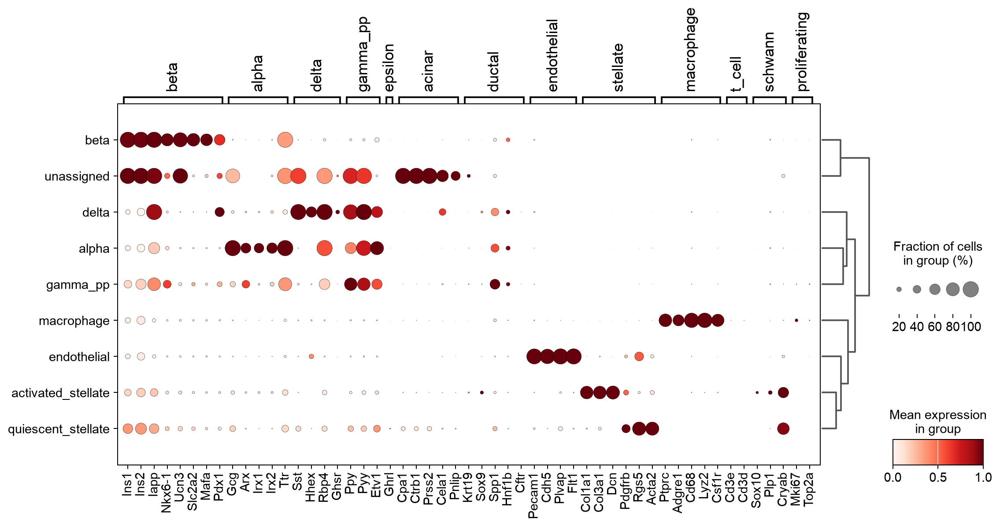

In [4]:
dot_markers = {k: [g for g in v if g in adata.var_names] for k, v in flat_markers.items()}
dot_markers = {k: v for k, v in dot_markers.items() if v}

sc.pl.dotplot(adata, dot_markers, groupby="level_2", standard_scale="var",
              dendrogram=True, show=False, figsize=(14, 6))
plt.savefig(cfg.FIG_DIR / "03_dotplot_level2.png", dpi=300, bbox_inches="tight")
plt.show()

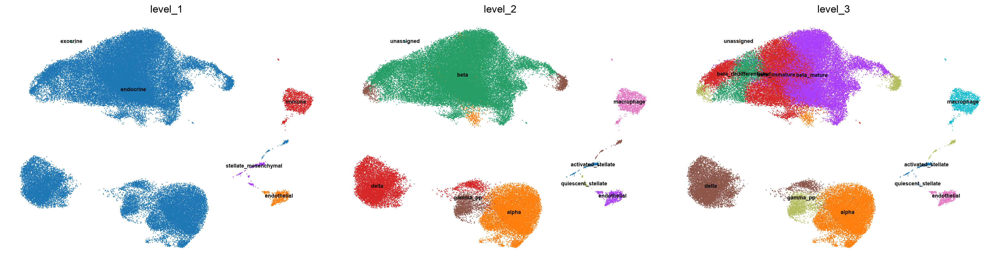

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, level in zip(axes, ["level_1", "level_2", "level_3"]):
    if level in adata.obs:
        sc.pl.umap(adata, color=level, ax=ax, show=False, frameon=False, size=5,
                   legend_loc="on data", legend_fontsize=7, title=level)
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03_umap_annotation_levels.png", dpi=300, bbox_inches="tight")

### 3.3 Catching residual doublets

Two independent signals should agree: scrublet's score from notebook 01, and
co-expression of markers that no single cell should carry. In islets the
classic case is `Ins1`+/`Gcg`+ — which is either a beta–alpha doublet or a
genuine bihormonal cell.

**This distinction matters in your experiment.** Bihormonal cells are a
documented feature of beta-cell dedifferentiation and stress. If Bola3 loss
pushes beta cells toward a dedifferentiated state, you would *expect* more
Ins+/Gcg+ cells in the KO — and if you filter them all out as doublets you will
have deleted the phenotype. The two are separated by doublet score and total
UMI count: a true bihormonal cell has a normal library size, a doublet has
roughly double.

Ins1+/Gcg+ cells: 4889 (6.21%)


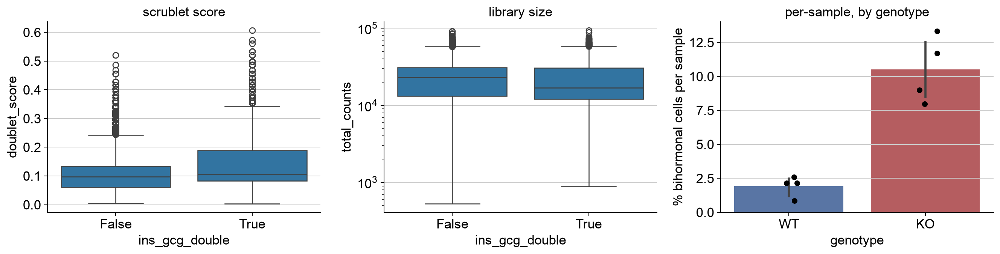

In [6]:
def coexpression_flag(adata, gene_a, gene_b, thresh=0.5):
    a = np.asarray(adata[:, gene_a].X.todense()).ravel()
    b = np.asarray(adata[:, gene_b].X.todense()).ravel()
    return (a > thresh) & (b > thresh)


if {"Ins1", "Gcg"} <= set(adata.var_names):
    adata.obs["ins_gcg_double"] = coexpression_flag(adata, "Ins1", "Gcg")
    dbl = adata.obs[adata.obs["ins_gcg_double"]]
    print(f"Ins1+/Gcg+ cells: {len(dbl)} ({100 * len(dbl) / adata.n_obs:.2f}%)")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.boxplot(data=adata.obs, x="ins_gcg_double", y="doublet_score", ax=axes[0])
    axes[0].set_title("scrublet score")
    sns.boxplot(data=adata.obs, x="ins_gcg_double", y="total_counts", ax=axes[1])
    axes[1].set_yscale("log"); axes[1].set_title("library size")
    prop = (adata.obs.groupby(["sample_id", "genotype"], observed=True)["ins_gcg_double"]
            .mean().mul(100).reset_index())
    sns.barplot(data=prop, x="genotype", y="ins_gcg_double", ax=axes[2],
                palette={"WT": "#4C72B0", "KO": "#C44E52"}, hue="genotype", legend=False)
    sns.stripplot(data=prop, x="genotype", y="ins_gcg_double", ax=axes[2],
                  color="k", size=6)
    axes[2].set_ylabel("% bihormonal cells per sample")
    axes[2].set_title("per-sample, by genotype")
    sns.despine(fig); fig.tight_layout()
    fig.savefig(cfg.FIG_DIR / "03_bihormonal.png", dpi=300, bbox_inches="tight")

The Bihormonal Ins+/Gcg+ population increasse by 5-fold in Bola3 KO. I am keeping these cells and the not removing them. The §3.3 step flags Ins1+/Gcg+ cells; it doesn't auto-delete them. 
Why the evidence says they're real bihormonal cells, not doublets. That's precisely what the two boxplots test, and they pass:

Library size (middle panel): the True (Ins1+/Gcg+) cells have essentially the same total counts as everyone else. A doublet is two cells in one droplet → ~2× library size. These aren't. This is the strongest signal.
Scrublet score (left panel): only marginally higher for the bihormonal cells (~0.12 vs ~0.09 median), nowhere near the doublet range.

Normal library size + near-normal doublet score = genuine bihormonal cells. If they were a doublet artifact, the KO increase could be dismissed as "KO just had more doublets" — but you already controlled the doublet rate (capped 6772/6785 at ~8%), and the library-size test rules it out directly. So the ~5× increase (WT ~2% → KO ~10.5%, with all 4 KO animals elevated and tight WT) is a real biological shift.
The biology is coherent and publishable. Ins+/Gcg+ bihormonal cells are a documented hallmark of beta-cell dedifferentiation/stress (T2D, FoxO1 loss, mitochondrial dysfunction models). BOLA3 is a mitochondrial Fe-S assembly factor → OXPHOS failure → metabolic stress → dedifferentiation → bihormonal is a clean, mechanistically-motivated story. Your framing ("bihormonal increase from Bola3-mediated beta-cell stress/dedifferentiation") is well-supported

### 3.4 Manual curation

Edit the mapping below after reading the dotplot. Start from the automatic
level-2 labels and override what is wrong. Keeping this as an explicit,
version-controlled dictionary — rather than clicking through an interactive
tool — is what makes the annotation reproducible.

In [7]:
# Automatic label -> final label. Anything absent passes through unchanged.
MANUAL_OVERRIDES: dict[str, str] = {
    # "gamma_pp": "gamma",
    # "stellate_mesenchymal": "stellate",
}

# Individual fine clusters you have decided are junk (doublets, stressed debris).
DROP_CLUSTERS: list[str] = [
]

# --- bihormonal (Ins1+/Gcg+) beta-cell state -------------------------------
# From §3.3 these passed the doublet test (normal library size), so they are
# genuine bihormonal cells, not artefacts. We split them out of the beta
# compartment as an explicit state so notebook 04 can test their proportion
# (expected higher in KO -> beta-cell dedifferentiation / stress).
# Which base labels are eligible to become bihormonal. Beta by default; add
# "unassigned" here ONLY after you've confirmed that cluster is bihormonal and
# not doublet/ambient junk.
BIHORMONAL_FROM: set[str] = {"beta"}
BIHORMONAL_LABEL = "beta_bihormonal"

adata.obs["cell_type"] = (adata.obs["level_2"].astype(str)
                          .map(lambda x: MANUAL_OVERRIDES.get(x, x)))

if DROP_CLUSTERS:
    keep = ~adata.obs["leiden_fine"].astype(str).isin(DROP_CLUSTERS)
    print(f"dropping {(~keep).sum()} cells from clusters {DROP_CLUSTERS}")
    adata = adata[keep].copy()

# relabel eligible bihormonal cells (after dropping, so junk can't be labelled)
if "ins_gcg_double" in adata.obs:
    bihorm = (adata.obs["ins_gcg_double"].astype(bool)
              & adata.obs["cell_type"].isin(BIHORMONAL_FROM))
    adata.obs.loc[bihorm, "cell_type"] = BIHORMONAL_LABEL
    n = int(bihorm.sum())
    by_geno = adata.obs.loc[bihorm, "genotype"].value_counts().to_dict()
    print(f"labelled {n} cells as '{BIHORMONAL_LABEL}'  (by genotype: {by_geno})")
    # fraction of each genotype's beta compartment that is bihormonal
    beta_like = adata.obs["cell_type"].isin(BIHORMONAL_FROM | {BIHORMONAL_LABEL})
    frac = (adata.obs.loc[beta_like]
            .assign(bh=lambda d: d["cell_type"] == BIHORMONAL_LABEL)
            .groupby("genotype", observed=True)["bh"].mean().mul(100).round(2))
    print(f"bihormonal as % of beta compartment:\n{frac.to_string()}")
else:
    print("WARNING: 'ins_gcg_double' not found — run §3.3 first; no bihormonal labelling done")

adata.obs["cell_type"] = pd.Categorical(adata.obs["cell_type"])

# a coarse grouping for figures where 12 categories is too many
COARSE = {
    "beta cells": "beta cells", "bihormonal_Ins+/Gcg+": "beta cells",
    "alpha cells": "alpha cells", "delta cells": "delta cells",
    "gamma/PP cells": "gamma/PP cells", "epsilon cells": "epsilon cells",
    "acinar cells": "acinar cells", "ductal cells": "ductal cells",
    "endothelial cells": "endothelial cells",
    "quiescent_stellate": "stellate cells", "activated_stellate": "stellate cells",
    "stellate_mesenchymal": "stellate cells",
    "macrophages": "macrophages", "t_cells": "immune cells", "b_cells": "immune cells", "immune cells": "immunes",
    "schwann_glia": "schwanns", "proliferating cells": "proliferating cells",
}
adata.obs["cell_type_coarse"] = pd.Categorical(
    adata.obs["cell_type"].astype(str).map(lambda x: COARSE.get(x, x))
)
display(pd.crosstab(adata.obs["cell_type"], adata.obs["genotype"]))

labelled 1080 cells as 'beta_bihormonal'  (by genotype: {'KO': 977, 'WT': 103})
bihormonal as % of beta compartment:
genotype
WT    0.45
KO    3.77


genotype,WT,KO
cell_type,,
activated_stellate,59,145
alpha,7391,6776
beta,22863,24933
beta_bihormonal,103,977
delta,6542,3085
endothelial,332,290
gamma_pp,1610,1853
macrophage,983,705
quiescent_stellate,42,55


### Composition per sample — a first look

Formal testing happens in notebook 04. This is the eyeball version, and it
tells whether notebook 04 is going to find anything.

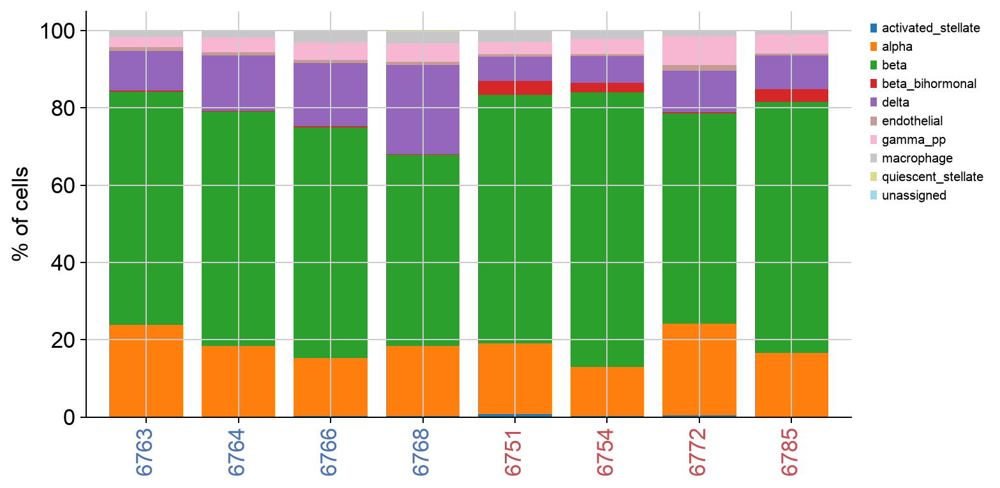

In [8]:
comp = (pd.crosstab(adata.obs["sample_id"], adata.obs["cell_type"], normalize="index") * 100)
order = adata.obs.groupby("sample_id", observed=True)["genotype"].first().sort_values().index
comp = comp.loc[order]

fig, ax = plt.subplots(figsize=(9, 4.5))
comp.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.8)
ax.set_ylabel("% of cells"); ax.set_xlabel("")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, frameon=False)
for i, sid in enumerate(comp.index):
    gt = adata.obs.loc[adata.obs.sample_id == sid, "genotype"].iloc[0]
    ax.get_xticklabels()[i].set_color("#C44E52" if gt == "KO" else "#4C72B0")
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03_composition_stacked.png", dpi=300, bbox_inches="tight")

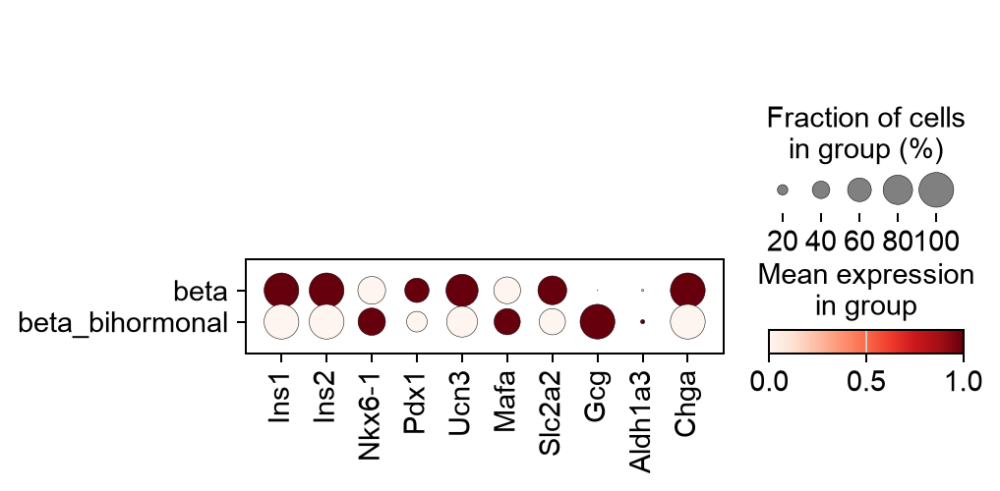

In [9]:
sub = adata[adata.obs["cell_type"].isin(["beta", "beta_bihormonal"])].copy()
genes = ["Ins1", "Ins2", "Nkx6-1", "Pdx1", "Ucn3", "Mafa", "Slc2a2",
         "Gcg", "Aldh1a3", "Chga"]
genes = [g for g in genes if g in adata.var_names]
sc.pl.dotplot(sub, genes, groupby="cell_type", standard_scale="var")

The dotplot confirms it. Reading the two rows (each gene scaled across the two groups):

Maturity/identity markers down in beta_bihormonal: Nkx6-1, Pdx1, Ucn3, Mafa, Slc2a2 are all darker in beta and lighter in beta_bihormonal. Loss of the beta transcription factors (Nkx6-1, Pdx1) and the functional maturity markers (Ucn3, Mafa, Slc2a2) is the core dedifferentiation signature.
Gcg gained (dark in bihormonal, absent in beta) — the bihormonal identity itself.
Aldh1a3 trending up in bihormonal — the canonical dedifferentiation marker.

So beta_bihormonal isn't a random Gcg-contaminated subset — it's a coherent dedifferentiated beta-cell state: reduced identity + reduced maturity + Aldh1a3/Gcg gain. That's exactly the "Bola3 loss → metabolic stress → dedifferentiation" story, now validated at the marker level. Solid figure material.
Next, run §3.5 (Beta cell substates) — this is the right follow-through and where your phenotype most likely lives. It re-embeds beta cells on their own (so the axes separate beta substates rather than beta-from-alpha) and scores three programs:

mature: Ucn3, Mafa, Slc2a2
immature: Mafb, Npy, Rbp4
dedifferentiated: Aldh1a3 + de-repressed "disallowed" genes (Ldha, Slc16a1/Mct1) that mature beta cells actively silence

The disallowed-gene angle is particularly apt for you: Ldha and Mct1 de-repression is a metabolic-dysfunction hallmark, and a mitochondrial Fe-S lesion that blocks ATP generation is exactly the kind of insult expected to push beta cells down the mature→dedifferentiated axis (beta maturity is metabolically enforced).

### 3.5 Beta cell substates

This is where the phenotype most plausibly lives, so it gets its own
subclustering. Beta cells are re-embedded on their own — subclustering within
the global embedding inherits axes that were chosen to separate beta from
alpha, not to separate beta substates from each other.

The three states scored:
- **mature**: `Ucn3`, `Mafa`, `Slc2a2` — glucose-responsive, fully functional
- **immature**: `Mafb`, `Npy`, `Rbp4` — neonatal-like programme
- **dedifferentiated**: `Aldh1a3`, plus de-repression of the "disallowed" genes
  `Ldha` and `Slc16a1` that mature beta cells actively silence

A mitochondrial lesion that prevents beta cells from generating ATP is expected
to push them along the mature → dedifferentiated axis, because functional
maturity in beta cells is metabolically enforced.

In [10]:
beta = adata[adata.obs["cell_type"] == "beta"].copy()
print(f"{beta.n_obs:,} beta cells "
      f"({beta.obs.groupby('genotype', observed=True).size().to_dict()})")

sc.pp.highly_variable_genes(beta, n_top_genes=1500, flavor="seurat_v3",
                            batch_key="sample_id", layer="counts")
beta.var["highly_variable"] &= ~beta.var_names.isin(ambient_prone)

_h = beta[:, beta.var["highly_variable"]].copy()
sc.pp.scale(_h, max_value=10)
sc.tl.pca(_h, n_comps=30, svd_solver="arpack", random_state=cfg.RANDOM_SEED)
beta.obsm["X_pca"] = _h.obsm["X_pca"]
del _h

if cfg.INTEGRATION_METHOD == "harmony":
    harmony_integrate(beta, key="sample_id", basis="X_pca",
                      adjusted_basis="X_pca_harmony", theta=1.5,
                      random_state=cfg.RANDOM_SEED)
    beta_basis = "X_pca_harmony"
else:
    beta_basis = "X_pca"

sc.pp.neighbors(beta, use_rep=beta_basis, n_neighbors=20, metric=cfg.KNN_METRIC,
                random_state=cfg.RANDOM_SEED)
sc.tl.umap(beta, random_state=cfg.RANDOM_SEED)
sc.tl.leiden(beta, resolution=0.6, key_added="beta_cluster", flavor="igraph",
             n_iterations=2, directed=False, random_state=cfg.RANDOM_SEED)

47,796 beta cells ({'WT': 22863, 'KO': 24933})


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [11]:
sys.path.insert(0, str(cfg.RESOURCE_DIR))
from bola3_gene_sets import GENE_SETS, filter_sets

beta_sets = filter_sets(
    {k: GENE_SETS[k] for k in ["Beta_identity", "Beta_disallowed",
                               "Beta_dedifferentiation", "OXPHOS_all",
                               "Integrated_stress_response"]},
    beta.var_names, min_genes=4,
)
for name, genes in beta_sets.items():
    sc.tl.score_genes(beta, genes, score_name=f"score_{name}", random_state=cfg.RANDOM_SEED)

state_markers = {
    "mature": [g for g in ["Ucn3", "Mafa", "Slc2a2", "G6pc2"] if g in beta.var_names],
    "immature": [g for g in ["Mafb", "Npy", "Rbp4", "Chgb"] if g in beta.var_names],
    "dediff": [g for g in ["Aldh1a3", "Ldha", "Slc16a1", "Cd81"] if g in beta.var_names],
}
for name, genes in state_markers.items():
    if genes:
        sc.tl.score_genes(beta, genes, score_name=f"beta_{name}", random_state=cfg.RANDOM_SEED)

Genes not found in the object (usually fine -- filtered out at QC):
  OXPHOS_all                       missing  16: Atp5f1a, Atp5f1b, Atp5f1c, Atp5f1d, Atp5f1e, Atp5if1, Atp5mc1, Atp5mc2 ...
  Integrated_stress_response       missing   2: Gars1, Sars1


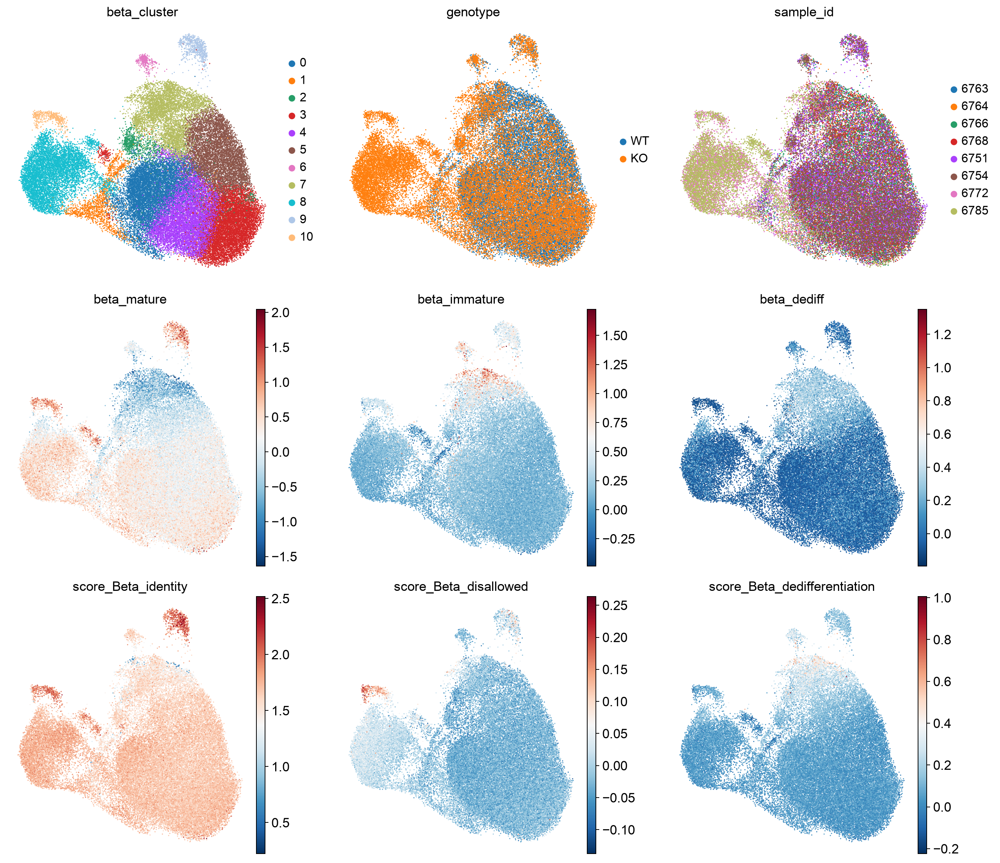

In [12]:
panels = (["beta_cluster", "genotype", "sample_id"]
          + [f"beta_{k}" for k in state_markers]
          + [f"score_{k}" for k in beta_sets])
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for ax, colour in zip(axes.flat, panels):
    sc.pl.umap(beta, color=colour, ax=ax, show=False, frameon=False, size=6,
               cmap="RdBu_r" if colour.startswith(("beta_", "score_")) else None,
               title=colour)
for ax in axes.flat[len(panels):]:
    ax.axis("off")
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03_beta_substates.png", dpi=300, bbox_inches="tight")

### Beta substate scores per sample

Plotted **per sample**, not per cell. With ~5,000 beta cells per mouse, a
per-cell test would return p < 1e-50 for a difference of no consequence — the
cells within a mouse are not independent observations of the genotype. Your
true sample size is 4 versus 4, and the plot should show that honestly.

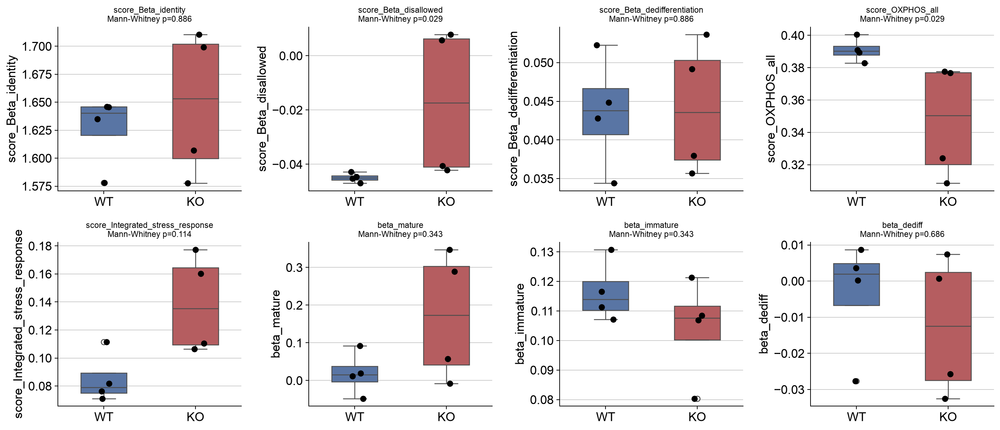

In [13]:
score_cols = [c for c in beta.obs.columns
              if c.startswith(("beta_", "score_"))
              and pd.api.types.is_numeric_dtype(beta.obs[c])]

per_sample = (beta.obs.groupby(["sample_id", "genotype"], observed=True)[score_cols]
              .mean().reset_index())

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, score_cols):
    sns.boxplot(data=per_sample, x="genotype", y=col, ax=ax, width=0.5,
                palette={"WT": "#4C72B0", "KO": "#C44E52"}, hue="genotype", legend=False)
    sns.stripplot(data=per_sample, x="genotype", y=col, ax=ax, color="k", size=7)
    from scipy.stats import mannwhitneyu

    w = per_sample.loc[per_sample.genotype == "WT", col]
    k = per_sample.loc[per_sample.genotype == "KO", col]
    p = mannwhitneyu(w, k).pvalue
    ax.set_title(f"{col}\nMann-Whitney p={p:.3f}", fontsize=9)
    ax.set_xlabel("")
for ax in axes.flat[len(score_cols):]:
    ax.axis("off")
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03_beta_scores_per_sample.png", dpi=300, bbox_inches="tight")

With n=4 per group the smallest possible Mann–Whitney p-value is 0.029, so a
result of "p = 0.029" means the groups separate perfectly and nothing more
precise than that. Treat these as descriptive. The properly powered test of
the same question is the pseudobulk model in notebook 05.

This is a good output. I am not removing any samples at this point and keeping the spread because it is not noise.
The two clean, significant results (both p=0.029, which is the floor at n=4 — perfect group separation):

**OXPHOS_all is DOWN in KO**. This is the direct, expected BOLA3 phenotype — a mitochondrial Fe-S cluster assembly factor failing → respiratory chain deficiency. Every KO animal sits below every WT animal. This is the mechanistic anchor.
**Beta_disallowed is UP in KO**. De-repression of the "disallowed" genes (Ldha, Mct1) that mature beta cells actively silence — a hallmark of metabolic dysfunction and loss of functional identity. Perfectly consistent with OXPHOS failure.
**ISR trends up (p=0.114)** — mitochondrial stress signature, in the right direction but not perfectly separated.

Why the dedifferentiation/mature scores look flat here (p=0.34–0.89) even though they clearly have a bihormonal phenotype: these scores are averaged over all beta cells per sample, and fully dedifferentiated cells are only ~3.8% of the KO beta compartment. A rare-cell signal gets diluted in a whole-population mean. That's expected — the dedifferentiation lives in a subpopulation (visible in the bihormonal count and marker dotplot), not in the bulk beta average. So there's no contradiction: pan-beta metabolic stress (OXPHOS↓, disallowed↑) affects most KO beta cells; full dedifferentiation is concentrated in a minority. That's a coherent graded story.
I am not removing the outlier samples becasue-

The KO spread is the mosaic-knockout signature. The KO is Pdx1-CreER on Bola3 fl/fl with variable recombination between animals. A KO mouse with high recombination shows a strong phenotype; one with low recombination shows a mild one. That between-animal variability is the dose-response biology — it's exactly what notebook 03b is built to explain, not something to delete.
Removing a sample because it's an outlier in the score I care about is outcome-dependent selection (p-hacking). With n=4, dropping to n=3 also guts the power and isn't defensible to a reviewer.
These Mann–Whitney values are descriptive only — the notebook says so. The properly powered test is the pseudobulk model in notebook 05, which handles this variance correctly.

There's no technical reason to drop anyone either: all 8 passed QC with balanced kept-counts, and the two overcalled KO samples (6772/6785) recovered cleanly.

What I am doing instead of removing them: proceed to 03b and get the per-mouse recombination rates. My prediction is that the "weak" KO animal(s) in these plots will turn out to be the low-recombination ones — which explains the spread rather than justifying deletion. If you want to see that now, add sample labels to the points (annotate each dot with sample_id); if one KO animal is consistently the mild outlier across OXPHOS/disallowed/ISR, that's almost certainly your lowest-recombination mouse, and 03b will confirm it.

So: save cell (03_beta_only.h5ad + 03_annotated.h5ad), keep all 8 samples, and go to 03b. 

In [14]:
beta.obs["beta_state"] = beta.obs["beta_cluster"]
adata.obs["beta_cluster"] = adata.obs_names.map(
    beta.obs["beta_cluster"].astype(str)).fillna("na")
for col in score_cols:
    adata.obs[col] = adata.obs_names.map(beta.obs[col]).astype(float)

beta.write_h5ad(cfg.DATA_DIR / "03_beta_only.h5ad")
adata.write_h5ad(cfg.H5AD["annotated"])
print(f"wrote -> {cfg.H5AD['annotated']}")

wrote -> /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output/processed/03_annotated.h5ad


### 3.6 Cluster markers for the record

In [15]:
sc.tl.rank_genes_groups(adata, "cell_type", method="wilcoxon", pts=True)
markers = sc.get.rank_genes_groups_df(adata, None)
markers = markers[(markers.pvals_adj < 0.05) & (markers.logfoldchanges > 0.5)]
markers.to_csv(cfg.TABLE_DIR / "03_cell_type_markers.csv", index=False)
print(f"wrote {len(markers)} marker rows -> {cfg.TABLE_DIR / '03_cell_type_markers.csv'}")
display(markers.groupby("group").head(5))

wrote 19408 marker rows -> /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output/tables/03_cell_type_markers.csv


,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,activated_stellate,Tmsb10,23.504087,4.592653,3.704453e-122,8.401329e-118,0.995098,0.823744
1,activated_stellate,Vim,23.402422,7.592100,4.037668e-121,4.578514e-117,0.965686,0.067493
2,activated_stellate,Sparc,23.071388,9.552764,8.973845e-118,6.783928e-114,0.941176,0.010960
3,activated_stellate,Igfbp7,23.047310,4.846343,1.565177e-117,8.874165e-114,0.995098,0.858318
4,activated_stellate,S100a6,23.013309,7.254971,3.429849e-117,1.555711e-113,0.950980,0.185167
22679,alpha,Gcg,184.912155,13.065994,0.000000e+00,0.000000e+00,0.996400,0.049804
22680,alpha,Ttr,182.912338,5.780700,0.000000e+00,0.000000e+00,0.998800,0.826932
22681,alpha,Higd1a,173.960907,5.966602,0.000000e+00,0.000000e+00,0.955107,0.047017
22682,alpha,Pcsk1n,173.835724,2.148918,0.000000e+00,0.000000e+00,0.998306,0.953973
22683,alpha,Gpx3,170.672852,4.475614,0.000000e+00,0.000000e+00,0.996612,0.367935


### 3.7 Final Cluster UMAP for the integrated WT and KO samples

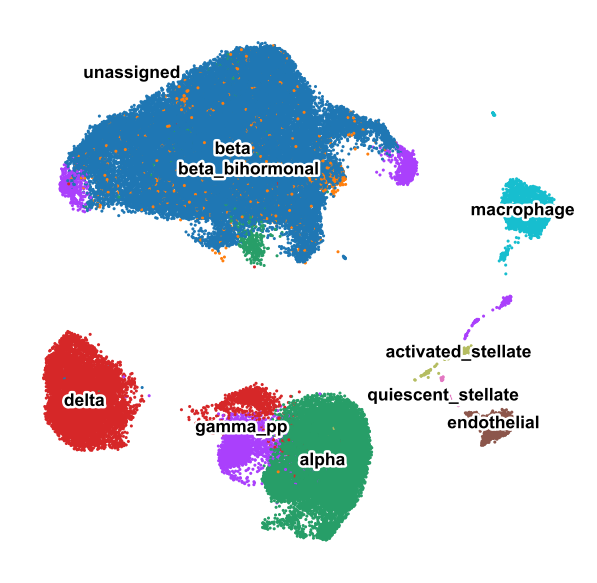

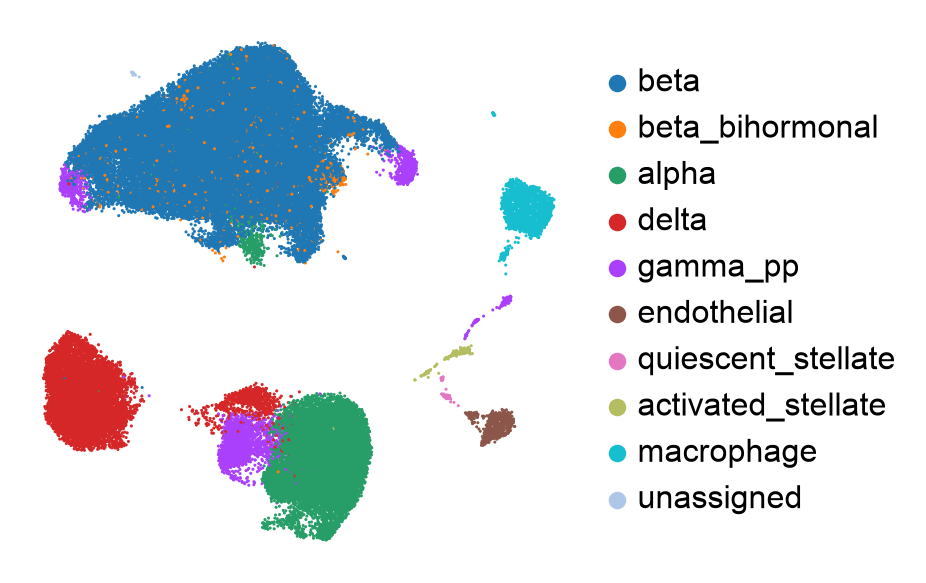

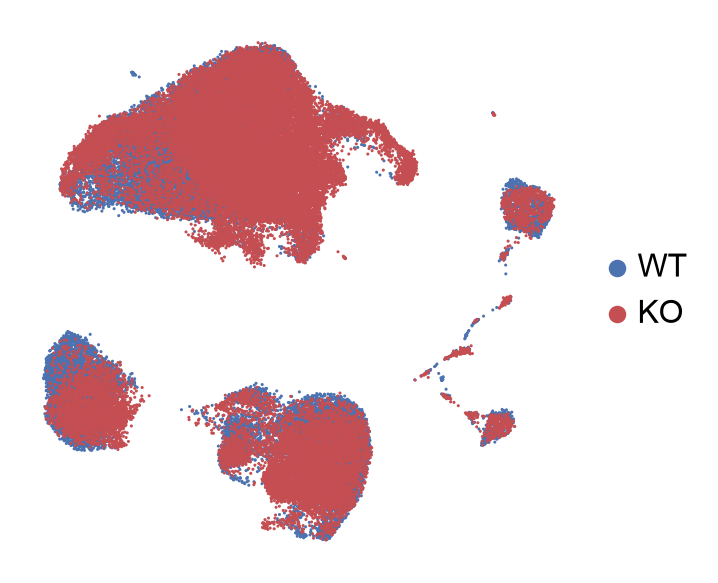

In [16]:
import scanpy as sc

sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False)

# order the legend sensibly (endocrine first, then exocrine/stroma/immune)
order = ["beta", "beta_bihormonal", "alpha", "delta", "gamma_pp", "epsilon",
         "acinar", "ductal", "endothelial",
         "quiescent_stellate", "activated_stellate", "macrophage", "immune"]
present = [c for c in order if c in adata.obs["cell_type"].cat.categories]
adata.obs["cell_type"] = adata.obs["cell_type"].cat.reorder_categories(
    present + [c for c in adata.obs["cell_type"].cat.categories if c not in present])

# (a) labels drawn on the clusters — the classic primary-figure panel
sc.pl.umap(adata, color="cell_type", legend_loc="on data",
           legend_fontsize=7, legend_fontoutline=2, frameon=False,
           title="", size=6, show=False)
import matplotlib.pyplot as plt
plt.savefig(cfg.FIG_DIR / "03_umap_celltypes_labeled.png", dpi=300, bbox_inches="tight")
plt.savefig(cfg.FIG_DIR / "03_umap_celltypes_labeled.pdf", bbox_inches="tight")  # vector, for the paper

# (b) side legend version — cleaner when labels overlap
sc.pl.umap(adata, color="cell_type", legend_loc="right margin",
           frameon=False, title="", size=6, show=False)
plt.savefig(cfg.FIG_DIR / "03_umap_celltypes_legend.png", dpi=300, bbox_inches="tight")

# (c) companion genotype panel — WT vs KO on the same embedding
sc.pl.umap(adata, color="genotype", frameon=False, title="", size=6,
           palette={"WT": "#4C72B0", "KO": "#C44E52"}, show=False)
plt.savefig(cfg.FIG_DIR / "03_umap_genotype.png", dpi=300, bbox_inches="tight")

### 3.7 Figures for the paper

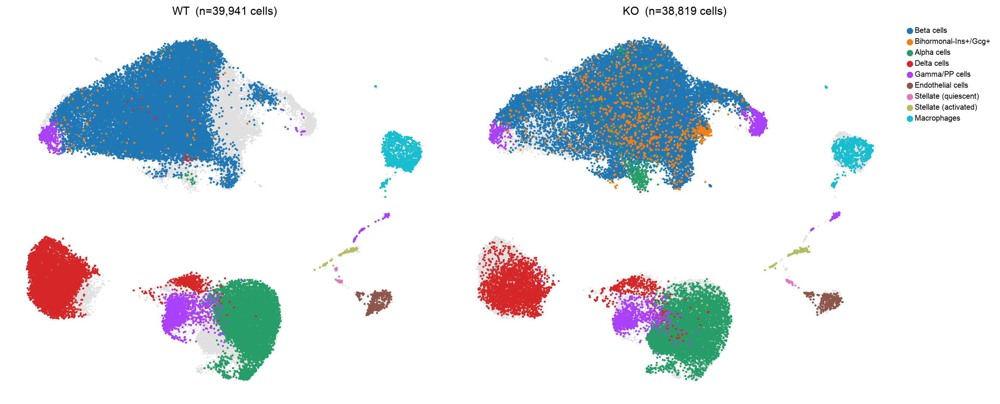

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False)

# ---------------------------------------------------------------------------
# 0. Pretty display labels (kept separate from the analysis label `cell_type`)
# ---------------------------------------------------------------------------
PRETTY = {
    "beta": "Beta cells", "beta_bihormonal": "Bihormonal-Ins+/Gcg+",
    "alpha": "Alpha cells", "delta": "Delta cells",
    "gamma_pp": "Gamma/PP cells", "epsilon": "Epsilon cells",
    "acinar": "Acinar cells", "ductal": "Ductal cells",
    "endothelial": "Endothelial cells",
    "quiescent_stellate": "Stellate (quiescent)",
    "activated_stellate": "Stellate (activated)",
    "macrophage": "Macrophages", "immune": "Immune cells",
}
order = ["Beta cells", "Bihormonal-Ins+/Gcg+", "Alpha cells", "Delta cells",
         "Gamma/PP cells", "Epsilon cells", "Acinar cells", "Ductal cells",
         "Endothelial cells", "Stellate (quiescent)", "Stellate (activated)",
         "Macrophages", "Immune cells"]
adata.obs["cell_type_pretty"] = (adata.obs["cell_type"].astype(str)
                                 .map(lambda x: PRETTY.get(x, x)))
cats = [c for c in order if c in set(adata.obs["cell_type_pretty"])]
adata.obs["cell_type_pretty"] = pd.Categorical(adata.obs["cell_type_pretty"],
                                               categories=cats, ordered=True)

# fixed colour per label so both panels match exactly
palette = dict(zip(cats, (sc.pl.palettes.default_20 * 2)[:len(cats)]))

# ---------------------------------------------------------------------------
# 1. WT vs KO cell-type maps, side by side (shared coords + colours,
#    other genotype greyed so density differences are visible)
# ---------------------------------------------------------------------------
xy = adata.obsm["X_umap"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, g in zip(axes, ["WT", "KO"]):
    ax.scatter(xy[:, 0], xy[:, 1], s=3, c="0.88", linewidths=0, rasterized=True)
    m = (adata.obs["genotype"] == g).values
    for ct in cats:
        mm = m & (adata.obs["cell_type_pretty"] == ct).values
        ax.scatter(xy[mm, 0], xy[mm, 1], s=5, c=palette[ct], label=ct,
                   linewidths=0, rasterized=True)
    ax.set_title(f"{g}  (n={int(m.sum()):,} cells)", fontsize=12); ax.axis("off")
axes[1].legend(markerscale=3, fontsize=8, frameon=False,
               bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03_umap_celltypes_WT_vs_KO.png", dpi=300, bbox_inches="tight")
fig.savefig(cfg.FIG_DIR / "03_umap_celltypes_WT_vs_KO.pdf", bbox_inches="tight")

# ---------------------------------------------------------------------------
# 2. Violin plots, WT vs KO (restricted to beta lineage, where these matter)
# ---------------------------------------------------------------------------
beta_sub = adata[adata.obs["cell_type"].isin(["beta", "beta_bihormonal"])].copy()

beta_id_genes = [g for g in ["Ins1", "Ins2", "Nkx6-1", "Pdx1", "Ucn3", "Mafa", "Slc2a2"]
                 if g in adata.var_names]
oxphos_genes  = [g for g in ["Bola3", "Sdhb", "Ndufs1", "Uqcrc2", "Cox5a",
                             "Atp5f1b", "Aco2", "Lias"] if g in adata.var_names]

for name, genes in [("beta_identity", beta_id_genes), ("oxphos_bola3", oxphos_genes)]:
    sc.pl.violin(beta_sub, keys=genes, groupby="genotype", stripplot=False,
                 rotation=0, show=False)
    plt.savefig(cfg.FIG_DIR / f"03_violin_{name}_WT_vs_KO.png", dpi=300, bbox_inches="tight")
    plt.close()

# ---------------------------------------------------------------------------
# 3. Feature maps on the full UMAP
# ---------------------------------------------------------------------------
sc.pl.umap(adata, color=beta_id_genes, ncols=4, cmap="viridis", size=5,
           frameon=False, show=False)
plt.savefig(cfg.FIG_DIR / "03_umap_beta_markers.png", dpi=300, bbox_inches="tight"); plt.close()

sc.pl.umap(adata, color=oxphos_genes, ncols=4, cmap="viridis", size=5,
           frameon=False, show=False)
plt.savefig(cfg.FIG_DIR / "03_umap_oxphos_bola3.png", dpi=300, bbox_inches="tight"); plt.close()

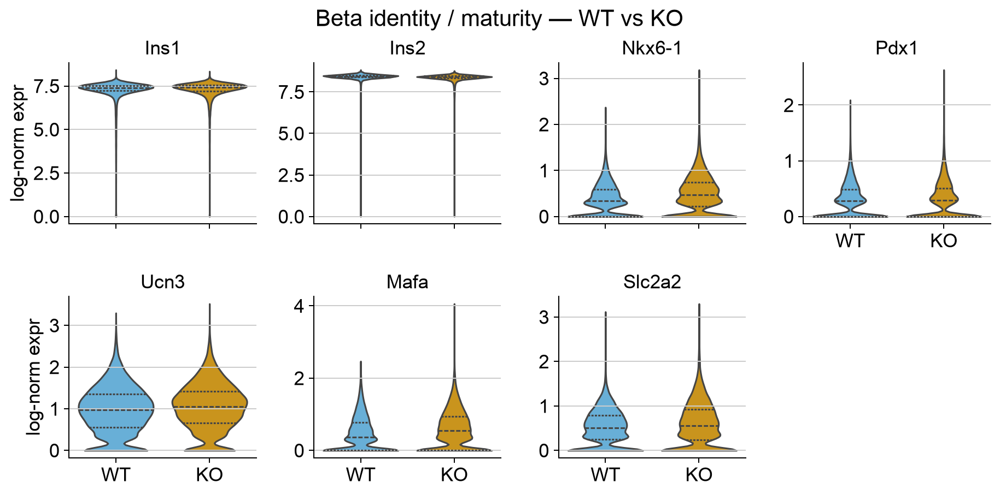

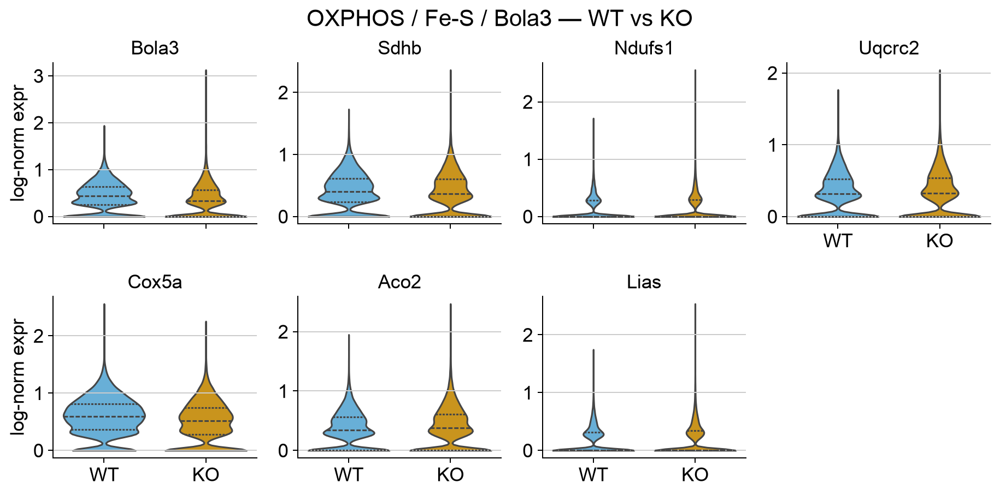

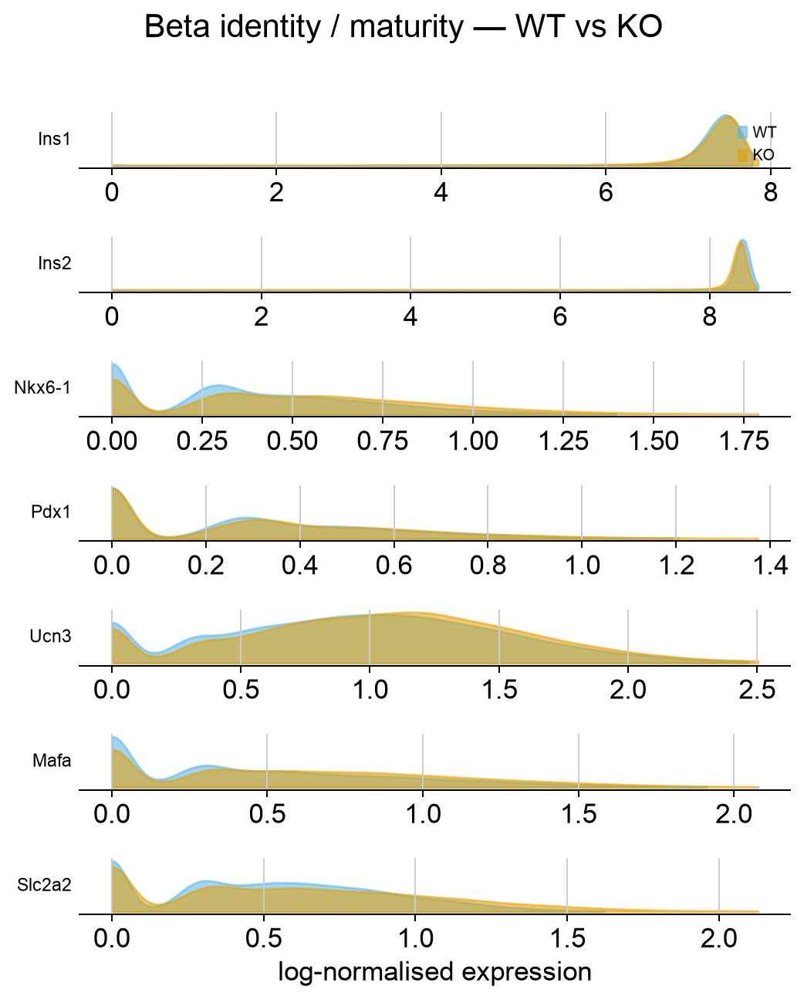

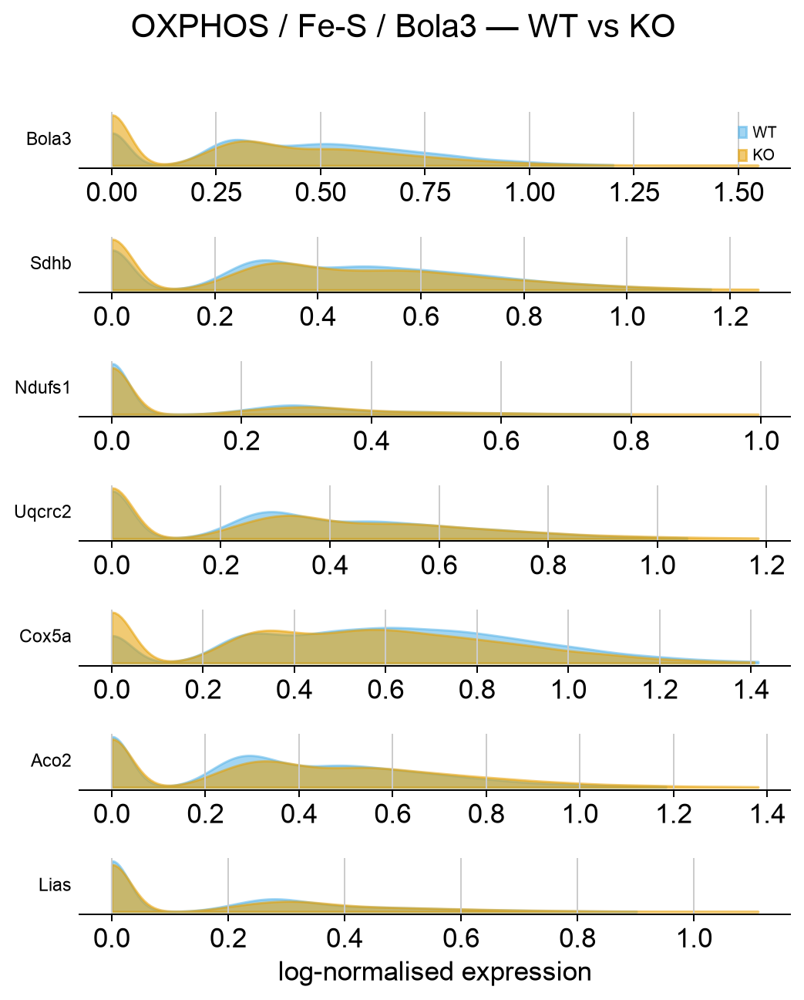

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy.stats import gaussian_kde

# Okabe-Ito colourblind-safe genotype palette
GENO_PAL = {"WT": "#56B4E9", "KO": "#E69F00"}
GENO_ORDER = ["WT", "KO"]

# beta lineage only, where these genes matter
beta_sub = adata[adata.obs["cell_type"].isin(["beta", "beta_bihormonal"])].copy()

beta_id_genes = [g for g in ["Ins1", "Ins2", "Nkx6-1", "Pdx1", "Ucn3", "Mafa", "Slc2a2"]
                 if g in adata.var_names]
oxphos_genes  = [g for g in ["Bola3", "Sdhb", "Ndufs1", "Uqcrc2", "Cox5a",
                             "Atp5f1b", "Aco2", "Lias"] if g in adata.var_names]

# LAYER: set to a lognorm layer name if adata.X is scaled; None uses adata.X
LAYER = None

# ---------------------------------------------------------------------------
# Violin grids, WT vs KO (seaborn -> custom colours + inline display)
# ---------------------------------------------------------------------------
def violin_grid(genes, name, title):
    df = sc.get.obs_df(beta_sub, keys=list(genes) + ["genotype"], layer=LAYER)
    melt = df.melt(id_vars="genotype", var_name="gene", value_name="expr")
    g = sns.catplot(data=melt, x="genotype", y="expr", col="gene", kind="violin",
                    order=GENO_ORDER, palette=GENO_PAL, hue="genotype",
                    hue_order=GENO_ORDER, legend=False, col_wrap=4, height=2.6,
                    sharey=False, inner="quartile", cut=0, density_norm="width")
    g.set_titles("{col_name}"); g.set_axis_labels("", "log-norm expr")
    g.figure.suptitle(title, y=1.02)
    g.figure.savefig(cfg.FIG_DIR / f"03_violin_{name}_WT_vs_KO.png",
                     dpi=300, bbox_inches="tight")
    plt.show()

violin_grid(beta_id_genes, "beta_identity", "Beta identity / maturity — WT vs KO")
violin_grid(oxphos_genes,  "oxphos_bola3",  "OXPHOS / Fe-S / Bola3 — WT vs KO")

# ---------------------------------------------------------------------------
# Ridge (ridgeline) plots, WT vs KO overlaid per gene
# ---------------------------------------------------------------------------
def ridge_plot(genes, name, title):
    df = sc.get.obs_df(beta_sub, keys=list(genes) + ["genotype"], layer=LAYER)
    genes = [g for g in genes if g in df.columns]
    n = len(genes)
    fig, axes = plt.subplots(n, 1, figsize=(6, 0.85 * n + 1.2))
    axes = np.atleast_1d(axes)
    for ax, gene in zip(axes, genes):
        for grp in GENO_ORDER:
            vals = df.loc[df["genotype"] == grp, gene].to_numpy()
            vals = vals[np.isfinite(vals)]
            if len(vals) < 5 or vals.std() == 0:
                continue
            xs = np.linspace(0, np.percentile(vals, 99.5) + 1e-6, 200)
            dens = gaussian_kde(vals)(xs)
            ax.fill_between(xs, dens, color=GENO_PAL[grp], alpha=0.55,
                            lw=1.2, edgecolor=GENO_PAL[grp], label=grp)
        ax.set_yticks([])
        ax.set_ylabel(gene, rotation=0, ha="right", va="center", fontsize=9)
        sns.despine(ax=ax, left=True)
    axes[0].legend(frameon=False, fontsize=8, loc="upper right")
    axes[-1].set_xlabel("log-normalised expression")
    fig.suptitle(title, y=1.01); fig.tight_layout()
    fig.savefig(cfg.FIG_DIR / f"03_ridge_{name}_WT_vs_KO.png", dpi=300, bbox_inches="tight")
    plt.show()

ridge_plot(beta_id_genes, "beta_identity", "Beta identity / maturity — WT vs KO")
ridge_plot(oxphos_genes,  "oxphos_bola3",  "OXPHOS / Fe-S / Bola3 — WT vs KO")

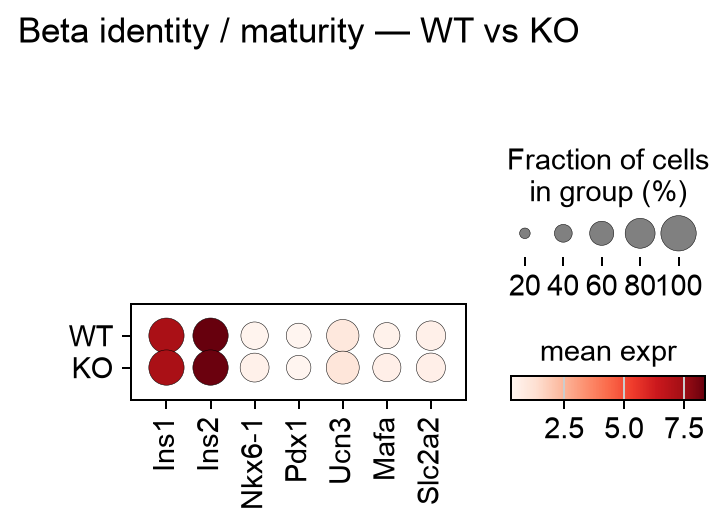

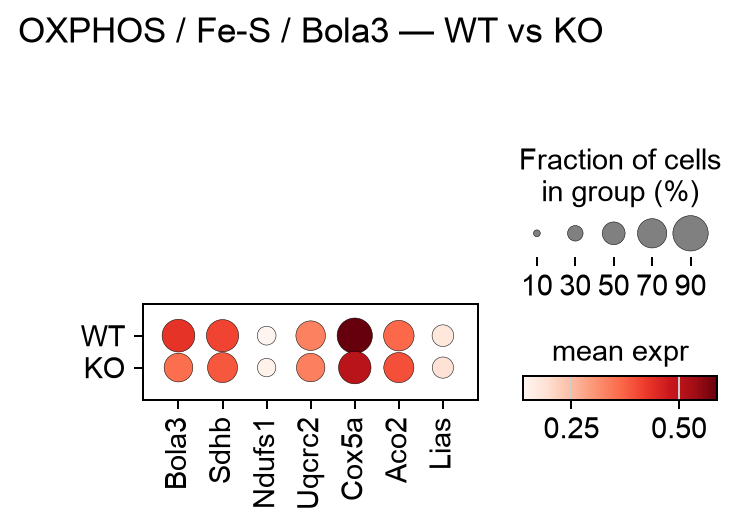

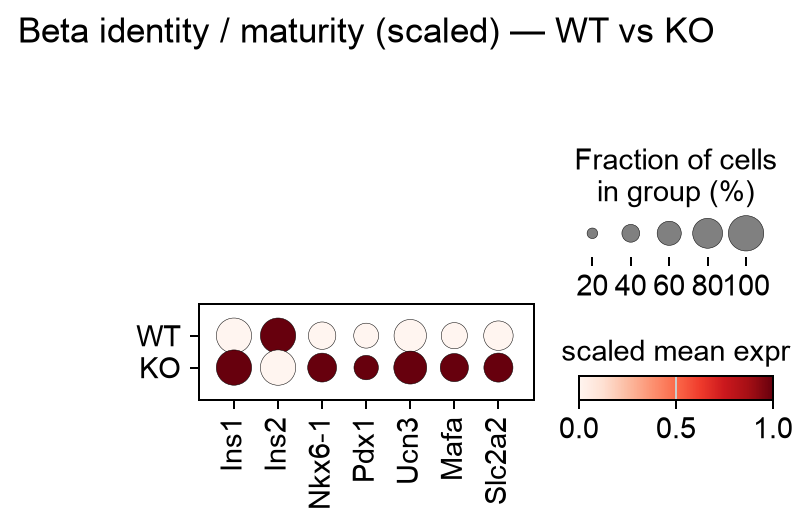

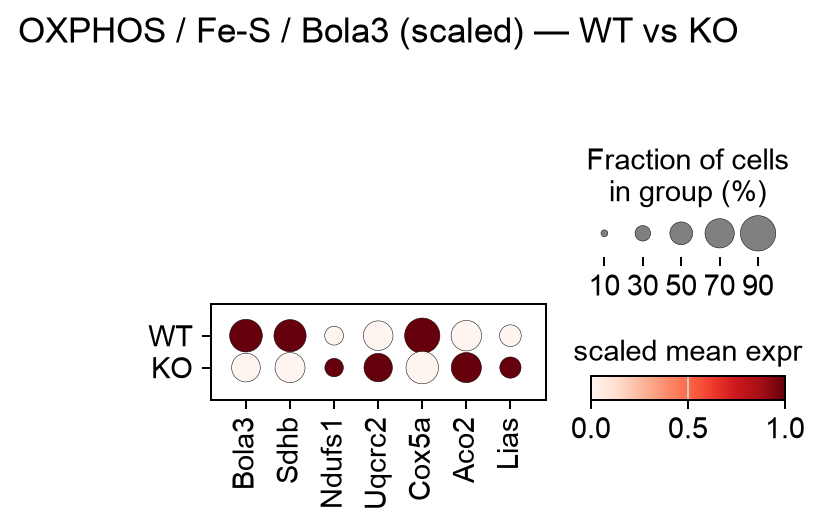

In [19]:
def dotplot_geno(genes, name, title, scale=False):
    sc.pl.dotplot(
        beta_sub, genes, groupby="genotype", layer=LAYER,
        categories_order=GENO_ORDER, cmap="Reds",
        standard_scale="var" if scale else None,
        colorbar_title="scaled mean expr" if scale else "mean expr",
        title=title, show=False,
    )
    tag = "scaled" if scale else "raw"
    plt.savefig(cfg.FIG_DIR / f"03_dotplot_{name}_{tag}_WT_vs_KO.png",
                dpi=300, bbox_inches="tight")
    plt.show()

# raw = absolute expression magnitude; scaled = direction per gene (0-1 across WT/KO)
dotplot_geno(beta_id_genes, "beta_identity", "Beta identity / maturity — WT vs KO")
dotplot_geno(oxphos_genes,  "oxphos_bola3",  "OXPHOS / Fe-S / Bola3 — WT vs KO")

dotplot_geno(beta_id_genes, "beta_identity", "Beta identity / maturity (scaled) — WT vs KO", scale=True)
dotplot_geno(oxphos_genes,  "oxphos_bola3",  "OXPHOS / Fe-S / Bola3 (scaled) — WT vs KO", scale=True)

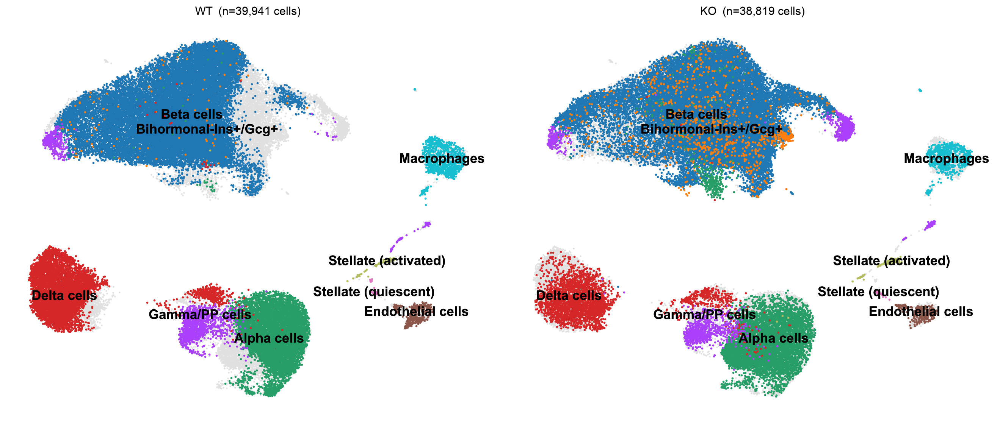

In [25]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import scanpy as sc

# uses cell_type_pretty, cats, palette from the earlier block; recompute cats/palette if needed
xy = adata.obsm["X_umap"]
labels = adata.obs["cell_type_pretty"].astype(str).values

# centroid (median is robust to stragglers) for each population, from the full embedding
centroids = {ct: (np.median(xy[labels == ct, 0]), np.median(xy[labels == ct, 1]))
             for ct in cats}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
for ax, g in zip(axes, ["WT", "KO"]):
    ax.scatter(xy[:, 0], xy[:, 1], s=3, c="0.88", linewidths=0, rasterized=True)
    m = (adata.obs["genotype"] == g).values
    for ct in cats:
        mm = m & (labels == ct)
        ax.scatter(xy[mm, 0], xy[mm, 1], s=5, c=palette[ct], linewidths=0, rasterized=True)
    # on-cluster labels
    for ct, (cx, cy) in centroids.items():
        ax.text(cx, cy, ct, fontsize=14, fontweight="bold", ha="center", va="center",
                color="black",
                path_effects=[pe.withStroke(linewidth=2.5, foreground="none")])
    ax.set_title(f"{g}  (n={int(m.sum()):,} cells)", fontsize=12); ax.axis("off")
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03_umap_celltypes_WT_vs_KO_labeled.png", dpi=300, bbox_inches="tight")
fig.savefig(cfg.FIG_DIR / "03_umap_celltypes_WT_vs_KO_labeled.pdf", bbox_inches="tight")
plt.show()

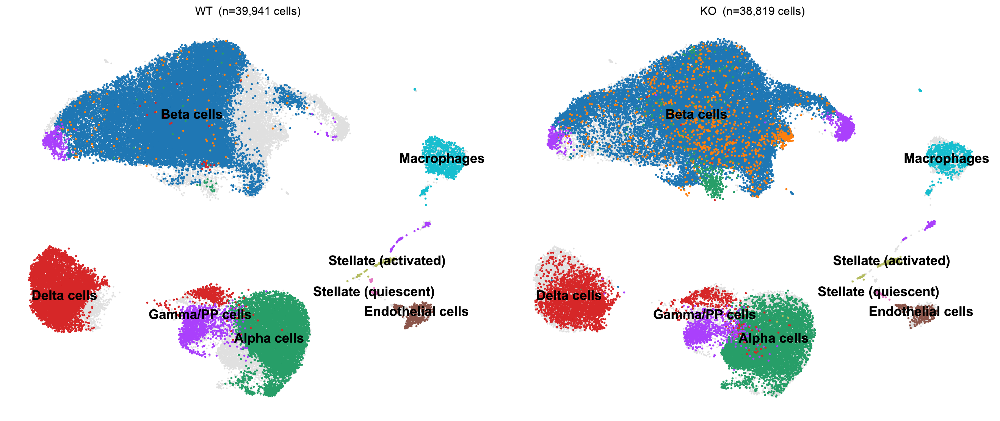

In [33]:
# uses cell_type_pretty, cats, palette from the earlier block; recompute cats/palette if needed
xy = adata.obsm["X_umap"]
labels = adata.obs["cell_type_pretty"].astype(str).values

# centroid (median is robust to stragglers) for each population, from the full embedding
centroids = {ct: (np.median(xy[labels == ct, 0]), np.median(xy[labels == ct, 1]))
             for ct in cats}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
for ax, g in zip(axes, ["WT", "KO"]):
    ax.scatter(xy[:, 0], xy[:, 1], s=3, c="0.88", linewidths=0, rasterized=True)
    m = (adata.obs["genotype"] == g).values
    for ct in cats:
        mm = m & (labels == ct)
        ax.scatter(xy[mm, 0], xy[mm, 1], s=5, c=palette[ct], linewidths=0, rasterized=True)
        # on-cluster labels — skip the bihormonal population (labelled via legend instead)
    SKIP = {ct for ct in cats if "bihormonal" in ct.lower()}
    for ct, (cx, cy) in centroids.items():
        if ct in SKIP:
            continue
        ax.text(cx, cy, ct, fontsize=14, fontweight="bold", ha="center", va="center",
                color="black",
                path_effects=[pe.withStroke(linewidth=2.5, foreground="none")])
    ax.set_title(f"{g}  (n={int(m.sum()):,} cells)", fontsize=12); ax.axis("off")
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03_umap_celltypes_WT_vs_KO_labeled.png", dpi=300, bbox_inches="tight")
fig.savefig(cfg.FIG_DIR / "03_umap_celltypes_WT_vs_KO_labeled.pdf", bbox_inches="tight")
plt.show()

---
### What to carry into notebook 04

- A cell type set you actually believe. If a population is annotated only by
  the automatic labels and you could not confirm it on the dotplot, either fix
  the marker YAML or merge it into its parent — do not carry an uncertain label
  into a compositional test.
- The bihormonal cell count per genotype. This is a candidate result.
- Whether beta cells split into substates at all. If they form one blob, the
  phenotype is a shift in degree, and notebook 05's pseudobulk DE is where you
  will find it.